### Marsch auf Mars – Lösung Schritt für Schritt

*31. Bundeswettbewerb Informatik (2012/2013), 2. Runde, Aufgabe 2*

Zum Bau einer Forschungsstation werden 100 identische autonome und mobile Roboter aus einem Raumshuttle auf die Marsoberfläche
abgeworfen. Das Shuttle kann die Roboter nur einzeln und in unregelmäßigen Zeitabständen abwerfen, so dass die Roboter nach dem
Abwurf zufällig über der Abwurfebene verstreut sind. Dabei wird aber sichergestellt, dass jeder Roboter (außer dem ersten) nur dann
abgeworfen wird, wenn sich im Umkreis von 200m seines Aufschlagpunktes bereits ein anderer Roboter befindet. Die Roboter müssen
sich nun an einem beliebigen Ort zusammenfinden.

Jeder Roboter kann sich mit einer Maximalgeschwindigkeit von 1m/s in eine frei wählbare Richtung bewegen. Er kann auch andere
Roboter in seiner Nähe erkennen und relativ zu seiner eigenen Position und Ausrichtung orten, aber dieser Mechanismus ist auf eine
Reichweite von 200m beschränkt. Die Roboter besitzen keine weiteren Fähigkeiten zur Kommunikation. Da keine Karten zur Verfügung
stehen, kann auch kein Treffpunkt von vornherein vereinbart werden.

Überlege dir ein Verfahren, das die Roboter verwenden können, um sich an einem gemeinsamen Ort zu treffen. Erstelle eine
Simulation, die die Bewegungen der Roboter mit deinem Verfahren von ihrer zufälligen Abwurfposition bis zum Zusammenfinden
graphisch darstellt. Beschreibe und diskutiere dein Verfahren anhand kommentierter Augenblicksbilder der Simulation.

#### Beispieldaten

Zu dieser Aufgabe gibt es keine Beispieldaten. Die Bewertungskriterien der Lösungshinweise nennen aber drei **Extremfälle**, bei
denen ein Verfahren auf jeden Fall funktionieren sollte. Wir haben sie in `beispieldaten/` gespeichert:
- `linie.txt`: 100 Roboter auf einer Geraden im Abstand von 200 m,
- `vieleck.txt`: 100 Roboter auf den Ecken eines regelmäßigen 100-Ecks mit der Seitenlänge 200 m,
- `raster.txt`: 100 Roboter auf einem 10 × 10-Raster mit dem Abstand 200 m.

In `eigene_testdaten/` liegen drei zufällige Abwürfe, die wir weiter unten selbst erzeugen: `abwurf_a.txt` und `abwurf_b.txt` so wie
in den Hinweisen beschrieben, `kette.txt` als „Kettenabwurf“ (jeder Roboter landet beim vorigen), der eine lange, verschlungene
Kette ergibt. Jede Zeile einer Datei enthält die Koordinaten `x y` eines Roboters in Metern, in der Reihenfolge des Abwurfs.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Simulation in Takten:** Wir lassen die Zeit in kleinen Schritten laufen. In jedem Takt schauen alle Roboter gleichzeitig um sich,
  entscheiden, wohin sie wollen, und fahren dann alle gleichzeitig ein Stück.
- **Rechnen mit Punkten in der Ebene:** Abstand zweier Punkte (Satz des Pythagoras), Richtung als Vektor der Länge 1, Schwerpunkt
  (Mittelwert der Koordinaten), Punkte auf einem Kreis mit `cos` und `sin`.
- **Graphen:** Die Roboter sind Knoten, zwei Roboter sind verbunden, wenn sie sich sehen (**Sichtgraph**). Mit einer
  **Tiefensuche** zählen wir, in wie viele Gruppen (Zusammenhangskomponenten) der Graph zerfällt.
- **Schnitt von Strahl und Kreis:** Wie weit kann man in eine Richtung fahren, ohne einen Kreis zu verlassen? Das führt auf eine
  **quadratische Gleichung**.
- **Kleinster umgebender Kreis:** der kleinste Kreis, der eine Menge von Punkten enthält. Wir berechnen ihn mit einem kurzen
  Verfahren, das Punkt für Punkt prüft, ob er schon drin ist (nach Welzl).
- **Verteilte Algorithmen:** Jeder Roboter rechnet für sich, es gibt keine zentrale Steuerung. Das Verfahren muss also so gebaut
  sein, dass alle Roboter mit *derselben* Regel ans Ziel kommen, obwohl jeder nur seine Umgebung kennt.

**Nützliche Funktionen und Bibliotheken**
- `math.hypot(dx, dy)` berechnet die Länge `√(dx² + dy²)`, `math.cos`, `math.sin`, `math.pi`, `math.sqrt`, `math.ceil` (aufrunden).
- `random.Random(startzahl)` liefert einen eigenen Zufallsgenerator. Mit derselben Startzahl kommen immer dieselben Zufallszahlen
  heraus, so dass man eine Simulation wiederholen kann. `zufall.uniform(a, b)` ist eine Kommazahl zwischen `a` und `b`,
  `zufall.randrange(n)` eine ganze Zahl von `0` bis `n - 1`.
- `matplotlib`: `scatter` zeichnet Punkte (auch unterschiedlich groß), `plt.Circle` einen Kreis, `subplots` mehrere Bilder nebeneinander.

## Die Idee in Worten

**Das Modell.** Wir legen zuerst fest, was wir annehmen (die Aufgabe lässt das offen, die Bewertungskriterien verlangen, dass man es
sagt):
- Die Roboter sind **Punkte**. „Treffen“ heißt: Alle stehen am selben Punkt. Echte Roboter würden ein paar Meter vorher anhalten.
- Die Roboter **starten gemeinsam**, wenn der letzte gelandet ist (das Shuttle sendet ein Signal, wie in den Hinweisen). Danach
  haben alle dieselbe Uhr.
- Alle **10 Sekunden** (ein **Takt**) orten alle Roboter gleichzeitig die anderen in höchstens 200 m Abstand, rechnen ein Ziel aus
  und fahren dann geradeaus darauf zu, höchstens 10 m weit (1 m/s). Bei der Ortung rechnen wir mit 1 mm Messgenauigkeit: Wer
  höchstens 200,001 m entfernt ist, wird gesehen.
- Jeder Roboter kennt nur die Lage der anderen **relativ zu sich selbst** in seinem eigenen Koordinatensystem. Wir verwenden deshalb
  nur Regeln, die nicht davon abhängen, wie das Koordinatensystem gedreht ist: Abstände, Mittelpunkte, Schwerpunkte und Kreise sehen
  in jedem Koordinatensystem gleich aus. Für die Simulation rechnen wir der Einfachheit halber in einem gemeinsamen
  Koordinatensystem; im Abschnitt „Für Neugierige“ prüfen wir, dass jeder Roboter dasselbe Ziel auch in seinem eigenen findet.
- Ein Roboter weiß, dass er fertig ist, wenn er die 99 anderen an seinem eigenen Ort sieht (die Zahl 100 ist bekannt).

**Was die Abwurfregel garantiert.** Jeder Roboter landet höchstens 200 m von einem früher gelandeten entfernt. Also hängt am Anfang
der **Sichtgraph zusammen**: Von jedem Roboter führt eine Kette von Robotern, die sich jeweils sehen, zum ersten. Das ist das
Einzige, worauf sich ein Verfahren verlassen kann.

**Drei Verfahren, eins nach dem anderen:**
1. **Schwerpunkt** (wie in den Lösungshinweisen): Jeder fährt zum Schwerpunkt der Roboter, die er sieht (sich selbst eingeschlossen).
   Das ist einfach und klappt oft, aber die Roboter können dabei **den Kontakt verlieren**. Dann zerfallen sie in Gruppen, die
   einander nie wieder finden.
2. **Schwerpunkt mit Abstandsregel:** Ein Roboter fährt nur so weit, dass er keinen Nachbarn verlieren kann, egal was der Nachbar
   tut. Die Gruppen können dann nicht mehr zerfallen. Leider kann es jetzt passieren, dass sich alle gegenseitig blockieren.
3. **Mitte des kleinsten Kreises mit Abstandsregel:** Statt des Schwerpunkts nimmt jeder den Mittelpunkt des kleinsten Kreises um
   alle Roboter, die er sieht. Für dieses Verfahren von Ando, Oasa, Suzuki und Yamashita (1999) ist bewiesen, dass die Roboter
   beliebig nahe zusammenrücken. In unserer Simulation treffen sie sich damit in allen Beispielen an einem Punkt.

Die Lösungshinweise gehen einen anderen Weg: Sie lassen Verfahren 1 laufen und vereinigen danach die Gruppen in einem aufwändigen
Verfahren, bei dem alle Roboter zu ihren Startpunkten zurückfahren (bis zu 46 Tage). Unsere Abstandsregel verhindert, dass Gruppen
überhaupt entstehen.

## Schritt 1: Abwurf und Einlesen

Zuerst die festen Größen. Dann lesen wir eine Datei mit den Orten der Roboter ein.

In [ ]:
import math
import random

SICHT = 200        # Reichweite der Ortung in m
TOLERANZ = 0.001   # Messgenauigkeit: 1 mm
TAKT = 10          # alle 10 s schauen die Roboter um sich
SCHRITT = 10       # höchstens 1 m/s, also höchstens 10 m je Takt
GLEICH = 1e-6      # näher als ein tausendstel Millimeter: derselbe Ort


def lies_orte(dateiname):
    """Liest Zeilen 'x y' und gibt eine Liste von Punkten (x, y) zurück."""
    orte = []
    with open(dateiname) as datei:
        for zeile in datei:
            teile = zeile.split()
            if len(teile) == 2:
                orte.append((float(teile[0]), float(teile[1])))
    return orte


def abstand(p, q):
    """Abstand der Punkte p und q (es zählen nur die ersten beiden Einträge, also x und y)."""
    return math.hypot(q[0] - p[0], q[1] - p[1])


def sieht(p, q):
    return abstand(p, q) <= SICHT + TOLERANZ


DATEIEN = ['beispieldaten/linie.txt', 'beispieldaten/vieleck.txt', 'beispieldaten/raster.txt',
           'eigene_testdaten/abwurf_a.txt', 'eigene_testdaten/abwurf_b.txt', 'eigene_testdaten/kette.txt']
orte_von = {}
for name in DATEIEN:
    orte_von[name] = lies_orte(name)
    print(f'{name:31} {len(orte_von[name])} Roboter')

beispieldaten/linie.txt         100 Roboter
beispieldaten/vieleck.txt       100 Roboter
beispieldaten/raster.txt        100 Roboter
eigene_testdaten/abwurf_a.txt   100 Roboter
eigene_testdaten/abwurf_b.txt   100 Roboter
eigene_testdaten/kette.txt      100 Roboter


Der **Abwurf** wie in den Lösungshinweisen: Der erste Roboter landet bei (0, 0). Für jeden weiteren wählen wir zufällig einen schon
gelandeten Roboter, einen Abstand `r` zwischen 0 und 200 m und eine Richtung (einen Winkel zwischen 0 und 2π). Mit `cos` und `sin`
wird daraus der Landepunkt. So ist sicher, dass jeder Roboter beim Landen einen anderen in Sichtweite hat, und die Roboter können
sich trotzdem in alle Richtungen verteilen.

Ein **Kettenabwurf** (immer neben dem *zuletzt* gelandeten Roboter) ist laut den Bewertungskriterien kein korrekter Abwurf, weil man
so nicht alle erlaubten Lagen bekommt. Wir nehmen ihn trotzdem als Testfall, weil er lange, dünne Ketten erzeugt, die für die
Verfahren schwierig sind.

In [ ]:
def abwurf(n, startzahl, kette=False):
    """n Roboter abwerfen; jeder landet höchstens 200 m neben einem schon gelandeten."""
    zufall = random.Random(startzahl)
    orte = [(0.0, 0.0)]
    while len(orte) < n:
        if kette:
            x, y = orte[-1]                                 # Kettenabwurf: neben dem letzten
        else:
            x, y = orte[zufall.randrange(len(orte))]        # neben einem zufälligen gelandeten Roboter
        r = zufall.uniform(0, SICHT)
        winkel = zufall.uniform(0, 2 * math.pi)
        orte.append((x + r * math.cos(winkel), y + r * math.sin(winkel)))
    return orte


def abwurf_ok(orte):
    """Sieht jeder Roboter (außer dem ersten) beim Landen einen früher gelandeten?"""
    for i in range(1, len(orte)):
        gefunden = False
        for j in range(i):
            if sieht(orte[i], orte[j]):
                gefunden = True
        if not gefunden:
            return False
    return True


def fast_gleich(orte1, orte2):
    """Stimmen zwei Listen von Orten bis auf Rundung (die Dateien haben 6 Nachkommastellen) überein?"""
    if len(orte1) != len(orte2):
        return False
    for i in range(len(orte1)):
        if abstand(orte1[i], orte2[i]) > 1e-5:
            return False
    return True


print('abwurf_a.txt = abwurf(100, 0):', fast_gleich(orte_von['eigene_testdaten/abwurf_a.txt'], abwurf(100, 0)))
print('abwurf_b.txt = abwurf(100, 1):', fast_gleich(orte_von['eigene_testdaten/abwurf_b.txt'], abwurf(100, 1)))
print('kette.txt = abwurf(100, 7, kette=True):', fast_gleich(orte_von['eigene_testdaten/kette.txt'], abwurf(100, 7, kette=True)))
for name in DATEIEN:
    print(f'{name:31} Abwurfregel erfüllt: {abwurf_ok(orte_von[name])}')

abwurf_a.txt = abwurf(100, 0): True
abwurf_b.txt = abwurf(100, 1): True
kette.txt = abwurf(100, 7, kette=True): True
beispieldaten/linie.txt         Abwurfregel erfüllt: True
beispieldaten/vieleck.txt       Abwurfregel erfüllt: True
beispieldaten/raster.txt        Abwurfregel erfüllt: True
eigene_testdaten/abwurf_a.txt   Abwurfregel erfüllt: True
eigene_testdaten/abwurf_b.txt   Abwurfregel erfüllt: True
eigene_testdaten/kette.txt      Abwurfregel erfüllt: True


Auch die drei Extremfälle erfüllen die Abwurfregel, wenn man sie in der Reihenfolge der Datei abwirft: Jeder Roboter hat einen
Vorgänger in genau 200 m Abstand. Gerade deshalb sind sie schwierig: Fährt ein Roboter auch nur ein kleines Stück von einem Nachbarn
weg, verliert er ihn aus den Augen.

So sehen die sechs Ausgangslagen aus. Bei den drei Abwürfen zeichnen wir um jeden Roboter seinen Sichtkreis mit 200 m Radius.

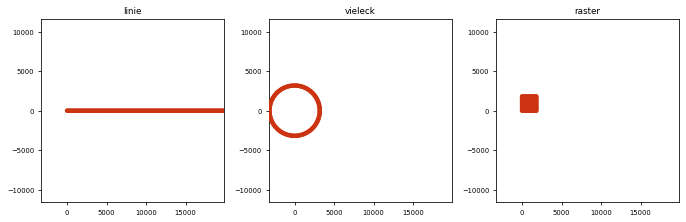

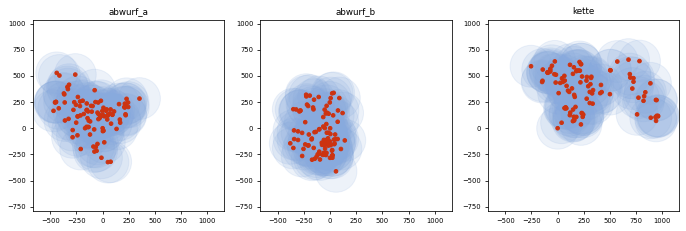

In [ ]:
import matplotlib.pyplot as plt


def zeichne_lagen(lagen, titel, kreise=False):
    """Zeichnet Lagen nebeneinander. Eine Lage ist eine Liste von (x, y, anzahl); je mehr Roboter, desto dicker der Punkt.
    Alle Bilder bekommen denselben Ausschnitt, damit man sie vergleichen kann."""
    fig, achsen = plt.subplots(1, len(lagen), figsize=(3.3 * len(lagen), 3.3), squeeze=False)
    xs, ys = [], []
    for lage in lagen:
        for x, y, anzahl in lage:
            xs.append(x)
            ys.append(y)
    rand = SICHT if kreise else 100
    mitte_x, mitte_y = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
    halb = max(max(xs) - min(xs), max(ys) - min(ys)) / 2 + rand      # quadratischer Ausschnitt um alle Lagen
    for k in range(len(lagen)):
        ax = achsen[0][k]
        lage = lagen[k]
        if kreise:
            for x, y, anzahl in lage:
                ax.add_patch(plt.Circle((x, y), SICHT, color='#88aadd', alpha=0.15))
        xs, ys, dicke = [], [], []
        for x, y, anzahl in lage:
            xs.append(x)
            ys.append(y)
            dicke.append(8 + 6 * anzahl)
        ax.scatter(xs, ys, s=dicke, color='#cc3311', zorder=3)
        ax.set_title(titel[k], fontsize=9)
        ax.set_xlim(mitte_x - halb, mitte_x + halb)
        ax.set_ylim(mitte_y - halb, mitte_y + halb)
        ax.set_aspect('equal')
        ax.tick_params(labelsize=7)
    plt.tight_layout()
    plt.show()


def als_lage(orte):
    """Am Anfang steht an jedem Ort ein Roboter."""
    lage = []
    for x, y in orte:
        lage.append((x, y, 1))
    return lage


zeichne_lagen([als_lage(orte_von[name]) for name in DATEIEN[:3]], ['linie', 'vieleck', 'raster'])
zeichne_lagen([als_lage(orte_von[name]) for name in DATEIEN[3:]], ['abwurf_a', 'abwurf_b', 'kette'], kreise=True)

Die Linie ist fast 20 km lang, das 100-Eck hat einen Durchmesser von über 6 km, das Raster ist 1,8 km breit. Die zufälligen Abwürfe
sind viel dichter: Weil jeder Roboter höchstens 200 m neben einem *zufälligen* früheren landet, wachsen sie wie ein Busch. Nur die
Kette wandert weiter weg.

## Schritt 2: Wer sieht wen?

Für die Simulation speichern wir jede Lage als Liste von **Haufen** `(x, y, anzahl)`: Roboter, die am selben Ort stehen, sehen genau
dasselbe und fahren deshalb auch genau gleich weiter. Wir können sie wie *einen* Roboter behandeln, der mehrfach zählt. Das spart
viel Rechenzeit, wenn sich die Roboter sammeln. Wegen Rundungsfehlern beim Rechnen mit Kommazahlen sehen wir zwei Orte als gleich an,
wenn sie weniger als `GLEICH` (ein tausendstel Millimeter) auseinander liegen.

`nachbarn` bestimmt für jeden Haufen die Nummern der Haufen, die er sieht. Das sind die Kanten des Sichtgraphen. `gruppen` zählt mit
einer Tiefensuche, in wie viele Teile der Sichtgraph zerfällt. Am Anfang muss das immer 1 sein.

In [ ]:
def zusammenfassen(liste):
    """liste: (x, y, anzahl). Haufen, die (fast) am selben Ort stehen, werden zu einem zusammengefasst."""
    haufen = []
    for x, y, anzahl in liste:
        gefunden = False
        for i in range(len(haufen)):
            hx, hy, ha = haufen[i]
            if abs(hx - x) < GLEICH and abs(hy - y) < GLEICH:
                haufen[i] = (hx, hy, ha + anzahl)
                gefunden = True
                break
        if not gefunden:
            haufen.append((x, y, anzahl))
    return haufen


def nachbarn(haufen):
    """nb[i] = Liste der Haufen, die Haufen i sieht (ohne i selbst)."""
    nb = []
    for i in range(len(haufen)):
        nb.append([])
    for i in range(len(haufen)):
        for j in range(i + 1, len(haufen)):
            if sieht(haufen[i], haufen[j]):
                nb[i].append(j)
                nb[j].append(i)
    return nb


def gruppen(haufen):
    """Anzahl der Zusammenhangskomponenten des Sichtgraphen (Tiefensuche mit Stapel)."""
    nb = nachbarn(haufen)
    besucht = [False] * len(haufen)
    anzahl = 0
    for start in range(len(haufen)):
        if not besucht[start]:
            anzahl += 1
            besucht[start] = True
            stapel = [start]
            while stapel:
                i = stapel.pop()
                for j in nb[i]:
                    if not besucht[j]:
                        besucht[j] = True
                        stapel.append(j)
    return anzahl


for name in DATEIEN:
    lage = zusammenfassen(als_lage(orte_von[name]))
    nb = nachbarn(lage)
    kanten = 0
    for liste in nb:
        kanten += len(liste)
    print(f'{name:31} {len(lage)} Haufen, {kanten // 2} Kanten im Sichtgraphen, {gruppen(lage)} Gruppe(n)')

beispieldaten/linie.txt         100 Haufen, 99 Kanten im Sichtgraphen, 1 Gruppe(n)
beispieldaten/vieleck.txt       100 Haufen, 100 Kanten im Sichtgraphen, 1 Gruppe(n)
beispieldaten/raster.txt        100 Haufen, 180 Kanten im Sichtgraphen, 1 Gruppe(n)
eigene_testdaten/abwurf_a.txt   100 Haufen, 1405 Kanten im Sichtgraphen, 1 Gruppe(n)
eigene_testdaten/abwurf_b.txt   100 Haufen, 1753 Kanten im Sichtgraphen, 1 Gruppe(n)
eigene_testdaten/kette.txt      100 Haufen, 937 Kanten im Sichtgraphen, 1 Gruppe(n)


Bei der Linie und beim 100-Eck sieht jeder Roboter nur seine zwei Nachbarn (99 bzw. 100 Kanten), beim Raster seine bis zu vier
Nachbarn links, rechts, oben und unten (180 Kanten; die Diagonale ist 283 m lang). In den zufälligen Abwürfen sieht ein Roboter
dagegen im Mittel 19 (Kette) bis 35 andere (jede Kante zählt für beide Enden: 2 · 1753 / 100 ≈ 35).

## Schritt 3: Verfahren 1 – zum Schwerpunkt

Der **Schwerpunkt** einer Gruppe von Punkten ist der Mittelwert ihrer x- und ihrer y-Koordinaten. Er ist der Punkt, zu dem die
Summe der quadrierten Abstände am kleinsten ist. Wichtig für uns: Er liegt in jedem Koordinatensystem am selben Ort, jeder Roboter
kann ihn also mit seinen eigenen Messungen berechnen. Ein Haufen mit `anzahl` Robotern zählt `anzahl`-mal.

Ein Takt läuft so ab: Alle bestimmen ihr Ziel aus der *alten* Lage, dann fahren alle gleichzeitig höchstens `SCHRITT` = 10 m darauf
zu. Den Parameter `verfahren` brauchen wir später für die anderen Verfahren. Zusätzlich gibt `takt` den längsten gefahrenen Weg
zurück: Ist er praktisch 0, bewegt sich nie wieder etwas, denn die Roboter haben kein Gedächtnis und sehen immer dasselbe.

In [ ]:
def ziel_schwerpunkt(i, haufen, nb):
    """Schwerpunkt aller Roboter, die Haufen i sieht, einschließlich seiner eigenen."""
    x, y, anzahl = haufen[i]
    summe_x, summe_y, summe_anzahl = x * anzahl, y * anzahl, anzahl
    for j in nb[i]:
        hx, hy, ha = haufen[j]
        summe_x += hx * ha
        summe_y += hy * ha
        summe_anzahl += ha
    return (summe_x / summe_anzahl, summe_y / summe_anzahl)


def neuer_ort(i, haufen, nb, verfahren):
    """Wohin fährt Haufen i in diesem Takt? Ergebnis: (x, y, gefahrener Weg)."""
    x, y, anzahl = haufen[i]
    if verfahren == 'kreis':
        zx, zy = ziel_kreis(i, haufen, nb)                 # kommt in Schritt 5
    else:
        zx, zy = ziel_schwerpunkt(i, haufen, nb)
    d = abstand((x, y), (zx, zy))
    if d < 1e-12:                                          # schon am Ziel
        return (x, y, 0)
    ux, uy = (zx - x) / d, (zy - y) / d                    # Richtung zum Ziel, Länge 1
    weg = min(d, SCHRITT)
    if verfahren != 'schwerpunkt':                         # Abstandsregel (Schritt 4)
        weg = min(weg, erlaubter_weg(i, haufen, nb, ux, uy))
    return (x + weg * ux, y + weg * uy, weg)


def takt(haufen, verfahren):
    """Ein Takt für alle Haufen gleichzeitig: Alle schauen auf die alte Lage, dann fahren alle.
    Ergebnis: neue Haufen und längster gefahrener Weg."""
    nb = nachbarn(haufen)
    neu = []
    laengster = 0
    for i in range(len(haufen)):
        nx, ny, weg = neuer_ort(i, haufen, nb, verfahren)
        neu.append((nx, ny, haufen[i][2]))
        laengster = max(laengster, weg)
    return zusammenfassen(neu), laengster


def simuliere(orte, verfahren, max_takte=20000, merken=False):
    """Lässt die Roboter laufen, bis alle an einem Ort sind, sich nichts mehr bewegt oder max_takte vorbei sind.
    Mit merken=True steht jede Lage in 'verlauf' (für die Bilder)."""
    haufen = zusammenfassen(als_lage(orte))
    verlauf = [haufen]
    t = 0
    ende = 'abgebrochen'
    while t < max_takte:
        if len(haufen) == 1:
            ende = 'getroffen'
            break
        neu, laengster = takt(haufen, verfahren)
        if laengster < 1e-9:
            ende = 'Stillstand'
            break
        haufen = neu
        t += 1
        if merken:
            verlauf.append(haufen)
    return {'takte': t, 'ende': ende, 'haufen': haufen, 'gruppen': gruppen(haufen), 'verlauf': verlauf}


def bericht(name, erg):
    zeit = erg['takte'] * TAKT
    text = f'{name:31} {erg["ende"]:11} nach {erg["takte"]:5} Takten ({zeit / 3600:5.2f} h), '
    return text + f'{len(erg["haufen"]):3} Orte, {erg["gruppen"]:2} Gruppe(n)'


erg1 = {}
for name in DATEIEN:
    erg1[name] = simuliere(orte_von[name], 'schwerpunkt', merken=True)
    print(bericht(name, erg1[name]))

beispieldaten/linie.txt         Stillstand  nach   623 Takten ( 1.73 h),  25 Orte, 25 Gruppe(n)
beispieldaten/vieleck.txt       getroffen   nach   747 Takten ( 2.08 h),   1 Orte,  1 Gruppe(n)
beispieldaten/raster.txt        Stillstand  nach    64 Takten ( 0.18 h),  13 Orte, 13 Gruppe(n)
eigene_testdaten/abwurf_a.txt   getroffen   nach    52 Takten ( 0.14 h),   1 Orte,  1 Gruppe(n)
eigene_testdaten/abwurf_b.txt   Stillstand  nach    34 Takten ( 0.09 h),   2 Orte,  2 Gruppe(n)
eigene_testdaten/kette.txt      Stillstand  nach    46 Takten ( 0.13 h),   2 Orte,  2 Gruppe(n)


Ausgegeben werden die Zahl der Takte (ein Takt = 10 Sekunden), die Zeit in Stunden, die Zahl der Orte, an denen am Ende Roboter
stehen, und die Zahl der Gruppen, die sich gegenseitig nicht mehr sehen.

**Nur das 100-Eck und `abwurf_a` treffen sich.** Bei allen anderen bleiben die Roboter in Gruppen stehen, die sich nicht sehen. Und
weil sich jede Gruppe für sich schon getroffen hat, bewegt sich nie wieder etwas: **Stillstand**. Beim 10 × 10-Raster entstehen
genau **13 Gruppen**, wie in Abbildung 5 der Lösungshinweise. Beim zufälligen Abwurf `abwurf_b` zerfallen die Roboter in zwei Gruppen
(wie in Abbildung 4 der Hinweise), ebenso bei der Kette.

**Ein Unterschied zu den Hinweisen:** Dort treffen sich die Roboter auf der Linie (Abbildung 3; laut den Hinweisen nur wegen
Rundungsfehlern). Bei uns zerfällt die Linie in 25 Gruppen. Wie es ausgeht, hängt also von Einzelheiten ab, zum Beispiel davon, wie
weit ein Roboter pro Takt fahren darf. Auf den Schwerpunkt allein kann man sich deshalb nicht verlassen.

Die Augenblicksbilder zeigen, was beim Raster passiert:

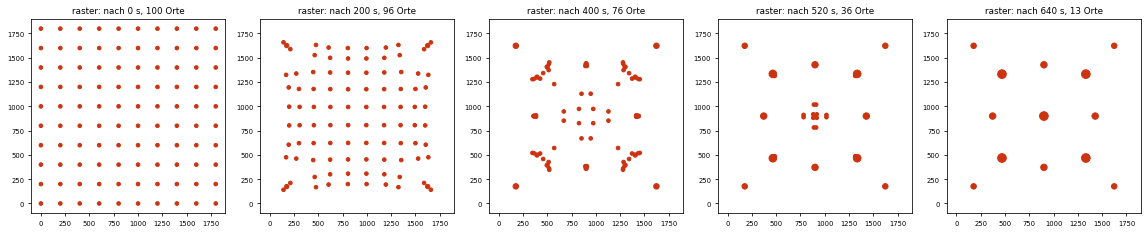

In [ ]:
def zeichne_verlauf(erg, zeitpunkte, name, kreise=False):
    lagen, titel = [], []
    for t in zeitpunkte:
        lagen.append(erg['verlauf'][t])
        titel.append(f'{name}: nach {t * TAKT} s, {len(erg["verlauf"][t])} Orte')
    zeichne_lagen(lagen, titel, kreise)


zeichne_verlauf(erg1['beispieldaten/raster.txt'], [0, 20, 40, 52, erg1['beispieldaten/raster.txt']['takte']], 'raster')

Im ersten Takt fahren die vier Eckroboter schräg nach innen (sie sehen nur zwei Nachbarn, der Schwerpunkt liegt innen), die übrigen
Randroboter ein Stück gerade nach innen. Die Roboter im Inneren bleiben zunächst stehen: Ihre vier Nachbarn liegen symmetrisch um sie
herum. Nach 200 s haben sich an den Ecken die ersten Haufen gebildet (96 Orte). Ein Haufen zieht die Roboter neben sich stark an,
weil er mehrfach zählt, und dabei reißen Verbindungen zu anderen Robotern ab. Nach 640 s stehen 13 Haufen in Abständen von mehr als
200 m: Keiner sieht einen anderen, also bleiben alle für immer stehen.

Bei `abwurf_b` sieht man, wie eine einzige Verbindung reißt. Wir zeichnen dazu die Sichtkreise:

Endlage: 73 und 27 Roboter


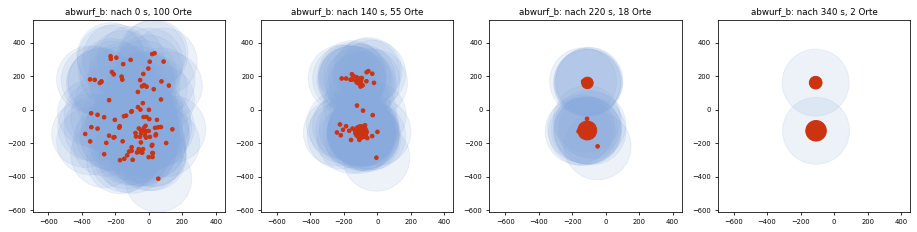

In [ ]:
zeichne_verlauf(erg1['eigene_testdaten/abwurf_b.txt'], [0, 14, 22, erg1['eigene_testdaten/abwurf_b.txt']['takte']], 'abwurf_b',
                kreise=True)
print('Endlage:', erg1['eigene_testdaten/abwurf_b.txt']['haufen'][0][2], 'und', erg1['eigene_testdaten/abwurf_b.txt']['haufen'][1][2],
      'Roboter')

Die meisten Roboter liegen unten dicht zusammen, oben liegt eine kleinere Gruppe, die nur über die Roboter in der Mitte mit dem Rest
verbunden ist. Diese Roboter werden von der großen Gruppe stärker angezogen als von der kleinen und fahren nach unten. Nach 220 s
sieht die obere Gruppe niemanden mehr aus der unteren. Beide sammeln sich für sich allein: 73 Roboter unten, 27 oben.

## Schritt 4: Verfahren 2 – keine Verbindung darf reißen

Das Problem von Verfahren 1: Ein Roboter fährt weg und verliert dabei einen Nachbarn. Wir brauchen eine Regel, mit der zwei
Roboter, die sich sehen, sich **auch nach dem Takt noch sehen**. Schwierig ist, dass ein Roboter nicht weiß, wohin sein Nachbar
fährt, denn sie können nicht miteinander reden.

**Die Abstandsregel** (nach Ando, Oasa, Suzuki und Yamashita): Sehen sich zwei Roboter A und B, betrachten beide den Kreis um die
**Mitte** zwischen ihnen mit dem Radius 100 m (halbe Sichtweite). Jeder fährt in diesem Takt höchstens so weit, dass er im Kreis
bleibt. Weil beide dieselbe Mitte und denselben Radius ausrechnen, sind danach beide im selben Kreis mit dem Durchmesser 200 m, also
höchstens 200 m voneinander entfernt. So eine Verbindung reißt nie, ganz egal, was die beiden sonst tun. Ein Roboter muss die Regel
für jeden seiner Nachbarn einhalten.

*(Einzelheit: Wegen der Messgenauigkeit können zwei Roboter bis zu 200,001 m auseinander sein. Dann nehmen wir als Radius den halben
Abstand, sonst stünde der Roboter schon außerhalb des Kreises.)*

**Wie weit darf man fahren?** Ein Roboter steht bei `p` und will in die Richtung `u` (Länge 1). Nach dem Weg `l` steht er bei
`p + l·u`. Er bleibt im Kreis mit Mittelpunkt `m` und Radius `r`, solange `|p + l·u − m| ≤ r`. Mit `a = p − m` heißt das
`|a + l·u|² ≤ r²`, ausmultipliziert `l² + 2·b·l + c ≤ 0` mit `b = a·u` (Skalarprodukt) und `c = |a|² − r²`. Die größte Lösung der
quadratischen Gleichung ist `l = −b + √(b² − c)`.

In [ ]:
def wie_weit(x, y, ux, uy, mx, my, r):
    """Wie weit kann man von (x, y) in Richtung (ux, uy) fahren, ohne den Kreis um (mx, my) mit Radius r zu verlassen?"""
    ax, ay = x - mx, y - my
    b = ax * ux + ay * uy
    c = ax * ax + ay * ay - r * r
    unter_der_wurzel = b * b - c
    if unter_der_wurzel < 0:          # nur bei Rundungsfehlern, wenn man genau auf dem Rand steht
        return 0
    return max(0, -b + math.sqrt(unter_der_wurzel))


def erlaubter_weg(i, haufen, nb, ux, uy):
    """Längster Weg in Richtung (ux, uy), bei dem Haufen i jeden Nachbarn sicher behält."""
    x, y, anzahl = haufen[i]
    weg = SCHRITT
    for j in nb[i]:
        qx, qy, qa = haufen[j]
        r = max(abstand((x, y), (qx, qy)), SICHT) / 2
        weg = min(weg, wie_weit(x, y, ux, uy, (x + qx) / 2, (y + qy) / 2, r))
    return weg


# Probe: zwei Roboter 200 m auseinander. Fährt A auf B zu, darf er 10 m weit (bis zu 200 m wären erlaubt).
# Fährt A senkrecht dazu, darf er gar nicht fahren: Er steht genau auf dem Rand des Kreises.
probe = [(0, 0, 1), (200, 0, 1)]
print(erlaubter_weg(0, probe, [[1], [0]], 1, 0), erlaubter_weg(0, probe, [[1], [0]], 0, 1))
probe = [(0, 0, 1), (150, 0, 1)]
print(erlaubter_weg(0, probe, [[1], [0]], 0, 1), round(wie_weit(0, 0, 0, 1, 75, 0, 100), 2))

10 0
10 66.14


Bei 150 m Abstand darf A senkrecht zur Verbindung die vollen 10 m fahren (die Abstandsregel allein erlaubt sogar 66,14 m).
Das erste Beispiel zeigt: Auf B zu darf A ebenfalls 10 m fahren, senkrecht dazu aber gar nicht. Steht der Nachbar aber genau
200 m entfernt, darf man nur in Richtungen fahren, die zu ihm hin zeigen. Das wird bei unseren Extremfällen wichtig.

Jetzt Verfahren 2: Ziel ist wieder der Schwerpunkt, aber mit Abstandsregel.

In [ ]:
erg2 = {}
for name in DATEIEN:
    erg2[name] = simuliere(orte_von[name], 'schwerpunkt mit regel', merken=(name == 'beispieldaten/raster.txt'))
    print(bericht(name, erg2[name]))

beispieldaten/linie.txt         getroffen   nach  9048 Takten (25.13 h),   1 Orte,  1 Gruppe(n)
beispieldaten/vieleck.txt       getroffen   nach   747 Takten ( 2.08 h),   1 Orte,  1 Gruppe(n)
beispieldaten/raster.txt        Stillstand  nach   112 Takten ( 0.31 h),  88 Orte,  1 Gruppe(n)
eigene_testdaten/abwurf_a.txt   getroffen   nach    52 Takten ( 0.14 h),   1 Orte,  1 Gruppe(n)
eigene_testdaten/abwurf_b.txt   getroffen   nach    46 Takten ( 0.13 h),   1 Orte,  1 Gruppe(n)
eigene_testdaten/kette.txt      getroffen   nach    81 Takten ( 0.23 h),   1 Orte,  1 Gruppe(n)


**Keine Gruppe zerfällt mehr**, am Ende ist überall nur noch eine Gruppe übrig. Die Linie, das 100-Eck und alle Abwürfe treffen
sich. Die Linie braucht dafür aber 9048 Takte, gut 25 Stunden. Und das Raster bleibt nach 112 Takten mit 88 Orten stehen, obwohl
sich alle noch sehen: **Stillstand**. Wir sehen uns die Endlage an und prüfen, warum keiner mehr fährt.

88 Orte, 60 davon wollen fahren und dürfen nicht
Abstände zum bremsenden Nachbarn: [200.0]


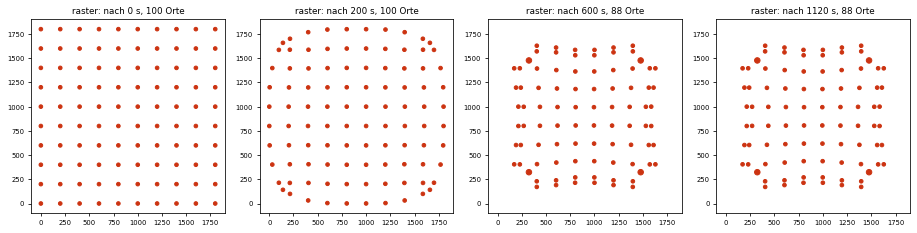

In [ ]:
def blockierte(haufen):
    """Für jeden Haufen, der zum Schwerpunkt will, aber nicht darf: Abstand zum Nachbarn, der ihn am stärksten bremst."""
    nb = nachbarn(haufen)
    abstaende = []
    for i in range(len(haufen)):
        x, y, anzahl = haufen[i]
        zx, zy = ziel_schwerpunkt(i, haufen, nb)
        d = abstand((x, y), (zx, zy))
        if d < 1e-9:
            continue
        ux, uy = (zx - x) / d, (zy - y) / d
        kleinster, bremser = SCHRITT, None
        for j in nb[i]:
            qx, qy, qa = haufen[j]
            r = max(abstand((x, y), (qx, qy)), SICHT) / 2
            w = wie_weit(x, y, ux, uy, (x + qx) / 2, (y + qy) / 2, r)
            if w < kleinster:
                kleinster, bremser = w, j
        abstaende.append(round(abstand(haufen[i], haufen[bremser]), 3))
    return abstaende


ende_raster = erg2['beispieldaten/raster.txt']['haufen']
bremsen = blockierte(ende_raster)
print(len(ende_raster), 'Orte,', len(bremsen), 'davon wollen fahren und dürfen nicht')
print('Abstände zum bremsenden Nachbarn:', sorted(set(bremsen)))
zeichne_verlauf(erg2['beispieldaten/raster.txt'], [0, 20, 60, erg2['beispieldaten/raster.txt']['takte']], 'raster')

60 der 88 Orte wollen weiterfahren, aber jeder davon hat einen Nachbarn in genau 200 m Abstand, von dem ihn der Weg zum
Schwerpunkt wegführen würde. Nach der Abstandsregel darf er das nicht, also bleibt er stehen. Die übrigen 28 stehen schon im
Schwerpunkt der Roboter, die sie sehen. Weil alle so warten, wartet jeder
für immer. Man nennt so etwas eine **Verklemmung** (englisch *deadlock*). Im Bild sieht man ein Gitter, das sich am Rand etwas
zusammengezogen hat; die Haufen werden durch das Ziehen der Nachbarn am Rand fest „verspannt“.

Auch die Linie ist ein Warnsignal: Ein Haufen am Ende zählt mehrfach und zieht seinen Schwerpunkt zu sich, daher kriecht er nur
langsam nach innen.

## Schritt 5: Verfahren 3 – zur Mitte des kleinsten Kreises

Ando, Oasa, Suzuki und Yamashita haben 1999 gezeigt, dass die Abstandsregel zusammen mit einem anderen Ziel immer funktioniert: Jeder
Roboter fährt zum **Mittelpunkt des kleinsten Kreises**, der alle Roboter enthält, die er sieht (sich selbst eingeschlossen). Anders
als beim Schwerpunkt zählt dabei nur, *wo* Roboter stehen, nicht wie viele es sind; ein dicker Haufen zieht also nicht stärker. Und
ein Roboter am Rand der Gruppe hat immer einen Grund, nach innen zu fahren. Auch der kleinste Kreis liegt in jedem
Koordinatensystem am selben Ort.

**Wie findet man den kleinsten Kreis?** Er wird immer von zwei Punkten (als Durchmesser) oder drei Punkten (als Umkreis eines
Dreiecks) auf seinem Rand festgelegt. Das folgende Verfahren (nach Welzl) geht die Punkte der Reihe nach durch und hält den kleinsten
Kreis um die bisherigen Punkte fest:
- Liegt der nächste Punkt `P` schon im Kreis, ändert sich nichts.
- Sonst muss `P` auf dem Rand des neuen Kreises liegen. Wir bauen den Kreis neu: zuerst nur um `P`, dann nehmen wir die früheren
  Punkte wieder dazu. Liegt einer davon, `Q`, draußen, nehmen wir den Kreis mit dem Durchmesser `PQ` und prüfen die Punkte vor `Q`;
  liegt davon einer, `R`, draußen, ist es der Umkreis von `P`, `Q` und `R`.

Das sind drei ineinander geschachtelte Schleifen, bei den paar Dutzend Punkten, die ein Roboter sieht, geht das schnell. Für den
**Umkreis** eines Dreiecks gibt es eine Formel für den Mittelpunkt (den Schnittpunkt der Mittelsenkrechten). Liegen die drei Punkte
auf einer Geraden, gibt es keinen Umkreis; dann nehmen wir den Kreis um die beiden äußeren.

In [ ]:
def kreis2(a, b):
    """Kreis mit der Strecke ab als Durchmesser: (mx, my, radius)."""
    mx, my = (a[0] + b[0]) / 2, (a[1] + b[1]) / 2
    return (mx, my, abstand((mx, my), a))


def kreis3(a, b, c):
    """Umkreis des Dreiecks abc (Schnittpunkt der Mittelsenkrechten, gerechnet mit a als Ursprung)."""
    bx, by = b[0] - a[0], b[1] - a[1]
    cx, cy = c[0] - a[0], c[1] - a[1]
    nenner = 2 * (bx * cy - by * cx)
    if abs(nenner) < 1e-12:                               # alle drei auf einer Geraden
        beste = kreis2(a, b)
        for k in [kreis2(a, c), kreis2(b, c)]:
            if k[2] > beste[2]:
                beste = k
        return beste
    ux = (cy * (bx * bx + by * by) - by * (cx * cx + cy * cy)) / nenner
    uy = (bx * (cx * cx + cy * cy) - cx * (bx * bx + by * by)) / nenner
    return (a[0] + ux, a[1] + uy, math.hypot(ux, uy))


def im_kreis(k, p):
    return abstand((k[0], k[1]), p) <= k[2] + 1e-7


def kleinster_kreis(punkte):
    """Kleinster Kreis um alle Punkte (nach Welzl, ohne Rekursion)."""
    k = (punkte[0][0], punkte[0][1], 0)
    for i in range(1, len(punkte)):
        if not im_kreis(k, punkte[i]):
            k = (punkte[i][0], punkte[i][1], 0)            # punkte[i] liegt auf dem Rand
            for j in range(i):
                if not im_kreis(k, punkte[j]):
                    k = kreis2(punkte[i], punkte[j])       # punkte[i] und punkte[j] auf dem Rand
                    for m in range(j):
                        if not im_kreis(k, punkte[m]):
                            k = kreis3(punkte[i], punkte[j], punkte[m])
    return k


def ziel_kreis(i, haufen, nb):
    punkte = [haufen[i]]
    for j in nb[i]:
        punkte.append(haufen[j])
    mx, my, r = kleinster_kreis(punkte)
    return (mx, my)


print(kleinster_kreis([(0, 0), (4, 0), (1, 1)]))                 # Durchmesser von (0, 0) nach (4, 0)
print(kleinster_kreis([(0, 0), (4, 0), (2, 3), (2, 1)]))         # Umkreis eines Dreiecks
print(kleinster_kreis([(0, 0), (2, 2), (1, 1)]))                 # drei Punkte auf einer Geraden

(2.0, 0.0, 2.0)
(2.0, 0.8333333333333335, 2.1666666666666665)
(1.0, 1.0, 1.4142135623730951)


Im ersten Beispiel liegt `(1, 1)` im Kreis mit dem Durchmesser von `(0, 0)` bis `(4, 0)`. Im zweiten liegen drei Punkte auf dem Rand,
der Mittelpunkt `(2, 0,8333…)` ist von `(0, 0)`, `(4, 0)` und `(2, 3)` gleich weit (2,1667) entfernt. Jetzt alle Beispiele mit
Verfahren 3:

In [ ]:
erg3 = {}
for name in DATEIEN:
    erg3[name] = simuliere(orte_von[name], 'kreis', merken=True)
    print(bericht(name, erg3[name]))

beispieldaten/linie.txt         getroffen   nach   990 Takten ( 2.75 h),   1 Orte,  1 Gruppe(n)
beispieldaten/vieleck.txt       getroffen   nach   512 Takten ( 1.42 h),   1 Orte,  1 Gruppe(n)
beispieldaten/raster.txt        getroffen   nach   128 Takten ( 0.36 h),   1 Orte,  1 Gruppe(n)
eigene_testdaten/abwurf_a.txt   getroffen   nach    53 Takten ( 0.15 h),   1 Orte,  1 Gruppe(n)
eigene_testdaten/abwurf_b.txt   getroffen   nach    41 Takten ( 0.11 h),   1 Orte,  1 Gruppe(n)
eigene_testdaten/kette.txt      getroffen   nach    69 Takten ( 0.19 h),   1 Orte,  1 Gruppe(n)


**Alle sechs Ausgangslagen treffen sich**, auch die drei Extremfälle der Bewertungskriterien. Und es geht deutlich schneller als mit
Verfahren 2: Die Linie braucht 990 statt 9048 Takte (2,75 Stunden), das Raster 128 Takte (gut 21 Minuten), die beiden zufälligen
Abwürfe weniger als 10 Minuten und die Kette knapp 12 Minuten.

Die kommentierten Augenblicksbilder:

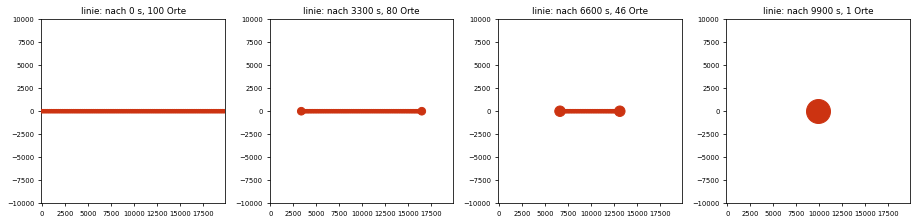

In [ ]:
def vier_bilder(name, kurz, kreise=False):
    erg = erg3[name]
    t = erg['takte']
    zeichne_verlauf(erg, [0, t // 3, 2 * t // 3, t], kurz, kreise)


vier_bilder('beispieldaten/linie.txt', 'linie')

**Linie:** Nur die beiden Endroboter haben ihren Nachbarn auf einer Seite und fahren nach innen; die anderen haben ihre beiden
Nachbarn symmetrisch um sich und bleiben zunächst stehen. Für einen Roboter am Ende ist der kleinste Kreis der Kreis über der Strecke
bis zum entferntesten Roboter, den er sieht; sein Mittelpunkt ist fast 100 m entfernt. Die Enden fahren also mit voller
Geschwindigkeit nach innen und sammeln unterwegs die Roboter ein (nach 3300 s steht bei x = 3348 m ein Haufen aus 9 Robotern). Nach
990 Takten = 9900 s stehen alle bei x = 9900 m, genau in der Mitte. Schneller geht es nicht: Wo auch immer der Treffpunkt liegt, einer der beiden
Endroboter ist mindestens 9900 m davon entfernt.

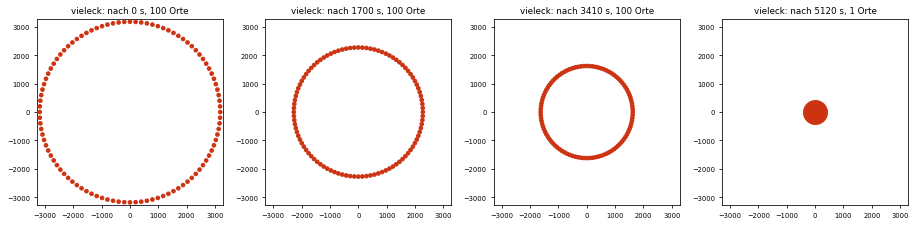

In [ ]:
vier_bilder('beispieldaten/vieleck.txt', 'vieleck')

**100-Eck:** Jeder Roboter sieht nur seine zwei Nachbarn. Der kleinste Kreis um die drei hat seinen Mittelpunkt in der Mitte
zwischen den beiden Nachbarn, am Anfang nur gut 6 m weiter innen. Der Ring zieht sich also langsam zusammen und bleibt dabei rund.
Je kleiner er wird, desto flacher sind die Knicke und desto kürzer ist dieser Weg: Der Ring wird immer langsamer (nach 1700 s ist
der Radius von 3183 m auf etwa 2250 m geschrumpft, nach 3410 s auf etwa 1600 m). Wenn die Roboter aber weniger als 100 m auseinander
stehen, sieht jeder zwei Nachbarn auf jeder Seite. Ab dann fährt der Ring mit voller Geschwindigkeit nach innen, bis sich alle in
der Mitte treffen.

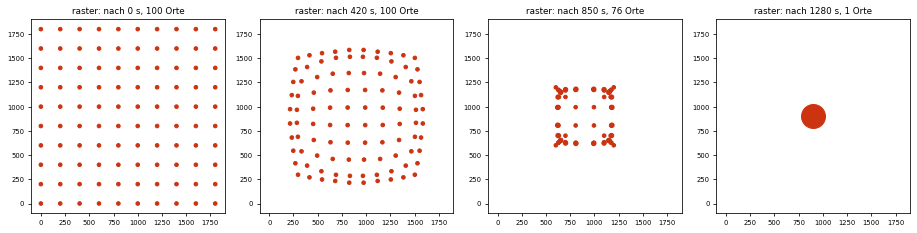

In [ ]:
vier_bilder('beispieldaten/raster.txt', 'raster')

**Raster:** Im ersten Takt bewegen sich nur die vier Ecken. Ein anderer Randroboter sieht links, rechts und innen je einen
Nachbarn, und der kleinste Kreis um diese vier Punkte hat ihn selbst als Mittelpunkt. Von den Ecken aus breitet sich die Bewegung aus,
das Raster wird rund und zieht sich zusammen (nach 850 s stehen die Roboter an 76 Orten in einem Quadrat von etwa 600 m). Nach 128
Takten ist es geschafft. Auch das ist die schnellste mögliche Zeit: Der kleinste Kreis um alle 100
Roboter hat den Radius 1272,8 m (die halbe Diagonale), so weit muss mindestens ein Roboter fahren.

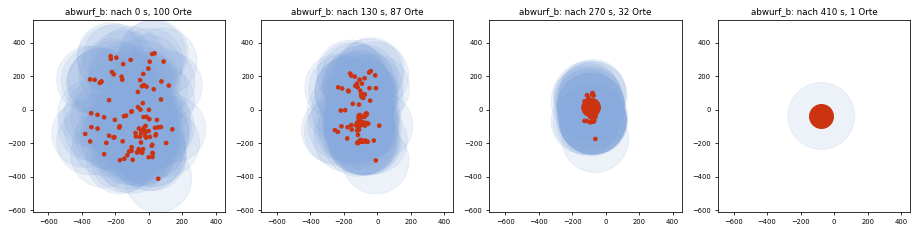

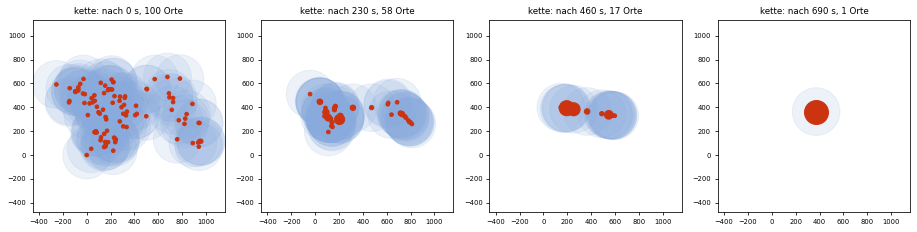

In [ ]:
vier_bilder('eigene_testdaten/abwurf_b.txt', 'abwurf_b', kreise=True)
vier_bilder('eigene_testdaten/kette.txt', 'kette', kreise=True)

**abwurf_b:** Die obere Gruppe, die bei Verfahren 1 abriss, bleibt jetzt dank der Abstandsregel verbunden, und beide Gruppen
laufen zusammen. **kette:** Die Kette zieht sich von ihren Enden und Knicken her zusammen. Wo sie eng
liegt, sehen sich mehr Roboter, und es entstehen Haufen, die weiter zusammenwachsen.

## Schritt 6: Wie lange dauert es?

Wie bei der Linie und beim Raster gibt es eine einfache **untere Schranke**: Ist `R` der Radius des kleinsten Kreises um *alle*
Roboter, dann ist jeder mögliche Treffpunkt von mindestens einem Roboter mindestens `R` entfernt. Mit 1 m/s braucht man also
mindestens `R` Sekunden, das sind `R / 10` Takte (aufgerundet). Die Roboter kennen `R` nicht, wir können es aber zum Vergleich
ausrechnen. Die Tabelle fasst alle drei Verfahren zusammen.

In [ ]:
def kurz(erg):
    if erg['ende'] == 'getroffen':
        return f'{erg["takte"]} Takte'
    return f'{erg["gruppen"]} Gr., {len(erg["haufen"])} Orte'


print(f'{"Datei":14} {"Verfahren 1":>17} {"Verfahren 2":>17} {"Verfahren 3":>13} {"Schranke":>9} {"Zeit 3":>8}')
for name in DATEIEN:
    mx, my, r = kleinster_kreis(orte_von[name])
    schranke = math.ceil((r - 0.01) / SCHRITT)
    zeit = erg3[name]['takte'] * TAKT
    datei = name.split('/')[1][:-4]
    print(f'{datei:14} {kurz(erg1[name]):>17} {kurz(erg2[name]):>17} {kurz(erg3[name]):>13} {schranke:>9} '
          f'{zeit // 60:5} min')

Datei                Verfahren 1       Verfahren 2   Verfahren 3  Schranke   Zeit 3
linie            25 Gr., 25 Orte        9048 Takte     990 Takte       990   165 min
vieleck                747 Takte         747 Takte     512 Takte       319    85 min
raster           13 Gr., 13 Orte    1 Gr., 88 Orte     128 Takte       128    21 min
abwurf_a                52 Takte          52 Takte      53 Takte        51     8 min
abwurf_b           2 Gr., 2 Orte          46 Takte      41 Takte        40     6 min
kette              2 Gr., 2 Orte          81 Takte      69 Takte        66    11 min


*(„Gr.“ = Gruppen; die Schranke ist in Takten angegeben. Wir ziehen 1 cm von `R` ab, damit Rundungsfehler beim Aufrunden nicht
stören.)*

Bei der **Linie** und beim **Raster** erreicht Verfahren 3 genau die Schranke, schneller geht es also nicht. Beim **100-Eck** braucht
es 512 statt mindestens 319 Takte, weil der Ring sich am Anfang nur langsam zusammenzieht (jeder Roboter sieht nur zwei Nachbarn und
darf kaum von ihnen weg). Bei den drei Abwürfen sind es nur 1 bis 3 Takte mehr als die Schranke. Alle Zeiten liegen unter drei
Stunden.

Zum Vergleich: Das Verfahren der Lösungshinweise kommt im schlimmsten Fall auf weniger als 46 Tage; das ist eine Schranke für alle
denkbaren Lagen, gemessen haben sie die Hinweise nicht. Eine solche allgemeine obere Schranke können wir für Verfahren 3 nicht
angeben. Ando und seine Mitautoren beweisen, dass sich die Roboter beliebig nahe kommen; in unserer Simulation stehen sie am Ende
wirklich an einem Punkt, weil eine Gruppe, in der sich alle sehen und die eng genug beisammen ist, in einem Takt zum gemeinsamen
Mittelpunkt fährt.

**Viele zufällige Abwürfe.** Zum Schluss testen wir je 10 weitere Abwürfe und Kettenabwürfe mit allen drei Verfahren.

In [ ]:
print(f'{"Abwurf":10} {"Verfahren 1":>21} {"Verfahren 2":>21} {"Verfahren 3":>21}')
test_zahlen = {}
for kette in [False, True]:
    for verfahren in ['schwerpunkt', 'schwerpunkt mit regel', 'kreis']:
        getroffen, laengste = 0, 0
        for startzahl in range(1000, 1010):
            erg = simuliere(abwurf(100, startzahl, kette), verfahren)
            if erg['ende'] == 'getroffen':
                getroffen += 1
                laengste = max(laengste, erg['takte'])
        test_zahlen[(kette, verfahren)] = (getroffen, laengste)
    zeile = f'{"Kette" if kette else "zufällig":10}'
    for verfahren in ['schwerpunkt', 'schwerpunkt mit regel', 'kreis']:
        getroffen, laengste = test_zahlen[(kette, verfahren)]
        zeile += f' {getroffen:>3} von 10, max. {laengste:4}'
    print(zeile)

Abwurf               Verfahren 1           Verfahren 2           Verfahren 3
zufällig     9 von 10, max.   62  10 von 10, max.   64  10 von 10, max.   57
Kette        1 von 10, max.   63  10 von 10, max.  517  10 von 10, max.  121


Ausgegeben ist, wie oft sich die Roboter getroffen haben, und die längste Zeit (in Takten) unter diesen Fällen. Verfahren 1 scheitert
schon bei einem der zufälligen Abwürfe und bei 9 von 10 Ketten. Verfahren 2 schafft hier alle, braucht bei einer Kette aber 517
Takte. Verfahren 3 trifft sich immer, spätestens nach 57 bzw. 121 Takten. Außerhalb des Notebooks haben wir je 100 Abwürfe getestet
(Startzahlen 1000 bis 1099): Verfahren 3 traf sich immer, spätestens nach 68 Takten (zufällig) bzw. 148 Takten (Kette). Verfahren 1
scheiterte bei 4 von 100 zufälligen Abwürfen und 96 von 100 Ketten. Verfahren 2 blieb bei 6 der 100 Ketten im Stillstand stecken und
brauchte bei einer anderen 2523 Takte (7 Stunden).

## Für Neugierige

### Jeder Roboter rechnet in seinem eigenen Koordinatensystem

Die Roboter haben keinen gemeinsamen Nordpol. Jeder ortet die anderen relativ zu sich selbst: Er steht im Ursprung, und seine
x-Achse zeigt in eine Richtung, die wir nicht kennen. Wir prüfen für einen Takt, dass das am Ergebnis nichts ändert: Jeder Roboter
bekommt eine zufällige Drehung, rechnet die Orte seiner Nachbarn in sein Koordinatensystem um, bestimmt dort das Ziel und den
erlaubten Weg und rechnet das Ergebnis zurück. Eine Drehung um den Winkel `w` ist `(x, y) → (x·cos w − y·sin w, x·sin w + y·cos w)`.

In [ ]:
def drehe(x, y, w):
    return (x * math.cos(w) - y * math.sin(w), x * math.sin(w) + y * math.cos(w))


def neuer_ort_eigene_sicht(i, haufen, nb, w):
    """Wie neuer_ort mit Verfahren 3, aber Haufen i rechnet in seinem eigenen, um w gedrehten Koordinatensystem."""
    x, y, anzahl = haufen[i]
    # Was Haufen i sieht: er selbst im Ursprung, die Nachbarn relativ zu ihm (verschoben und um -w gedreht)
    sicht = [(0, 0, anzahl)]
    sicht_nb = [[]]
    for j in nb[i]:
        qx, qy = drehe(haufen[j][0] - x, haufen[j][1] - y, -w)
        sicht.append((qx, qy, haufen[j][2]))
        sicht_nb[0].append(len(sicht) - 1)
    ex, ey, weg = neuer_ort(0, sicht, sicht_nb, 'kreis')    # gerechnet nur mit den eigenen Messungen
    dx, dy = drehe(ex, ey, w)                                # zurück in die gemeinsamen Koordinaten
    return (x + dx, y + dy)


zufall = random.Random(5)
for name in DATEIEN:
    lage = zusammenfassen(als_lage(orte_von[name]))
    nb = nachbarn(lage)
    unterschied = 0
    for i in range(len(lage)):
        gx, gy, weg = neuer_ort(i, lage, nb, 'kreis')
        eigen = neuer_ort_eigene_sicht(i, lage, nb, zufall.uniform(0, 2 * math.pi))
        unterschied = max(unterschied, abstand((gx, gy), eigen))
    print(f'{name:31} größter Unterschied nach einem Takt: {unterschied:.0e} m')

beispieldaten/linie.txt         größter Unterschied nach einem Takt: 9e-16 m
beispieldaten/vieleck.txt       größter Unterschied nach einem Takt: 8e-12 m
beispieldaten/raster.txt        größter Unterschied nach einem Takt: 1e-15 m
eigene_testdaten/abwurf_a.txt   größter Unterschied nach einem Takt: 5e-13 m
eigene_testdaten/abwurf_b.txt   größter Unterschied nach einem Takt: 1e-13 m
eigene_testdaten/kette.txt      größter Unterschied nach einem Takt: 1e-13 m


Die Unterschiede sind winzige Rundungsfehler (weit unter einem Mikrometer). Die Roboter brauchen also wirklich keinen gemeinsamen
Nordpol.

### Wie oft soll ein Roboter schauen?

Wir haben angenommen, dass die Roboter alle 10 Sekunden schauen. Was ändert sich, wenn sie öfter oder seltener schauen? Wir rechnen
das Raster und das 100-Eck mit Verfahren 3 noch einmal mit 5 und 20 Sekunden pro Takt (der Schritt ist dann 5 bzw. 20 m).

In [ ]:
for takt_neu in [5, 10, 20]:
    TAKT, SCHRITT = takt_neu, takt_neu
    zeile = f'alle {takt_neu:2} s:'
    for name in ['beispieldaten/raster.txt', 'beispieldaten/vieleck.txt']:
        erg = simuliere(orte_von[name], 'kreis')
        zeile += f'   {name.split("/")[1][:-4]} {erg["ende"]} nach {erg["takte"]:3} Takten = {erg["takte"] * TAKT:5} s'
    print(zeile)
TAKT, SCHRITT = 10, 10

alle  5 s:   raster getroffen nach 255 Takten =  1275 s   vieleck getroffen nach 684 Takten =  3420 s
alle 10 s:   raster getroffen nach 128 Takten =  1280 s   vieleck getroffen nach 512 Takten =  5120 s
alle 20 s:   raster getroffen nach  66 Takten =  1320 s   vieleck getroffen nach 459 Takten =  9180 s


Beim Raster ändert sich die Zeit kaum, beim 100-Eck dagegen sehr: Mit 20 Sekunden pro Takt braucht der Ring fast doppelt so lange,
mit 5 Sekunden geht es schneller. Der Ring wird nicht von der Geschwindigkeit gebremst: Jeder Roboter fährt pro Takt nur bis zur
Mitte zwischen seinen beiden Nachbarn, am Anfang gut 6 m weit, egal wie lang der Takt ist. Wer öfter schaut, kommt also schneller
voran.

### Warum Verfahren 3 funktioniert (Beweisidee)

- **Keine Verbindung reißt** (Abstandsregel). Der Sichtgraph bleibt also zusammenhängend; es können nur neue Kanten dazukommen.
- **Die Gruppe wird nie breiter:** Jeder Roboter fährt auf einer Strecke zu einem Punkt in der Hülle der Roboter, die er sieht. Die
  konvexe Hülle aller Roboter kann deshalb nur schrumpfen.
- **Es geht immer voran:** Der Beweis von Ando und seinen Mitautoren zeigt (grob gesagt), dass der kleinste Kreis um *alle* Roboter
  immer weiter schrumpft, solange sie nicht an einem Punkt stehen. Mit dem Schwerpunkt als Ziel gilt das nicht, wie die Verklemmung
  beim Raster zeigt.

Daraus folgt, dass die Roboter beliebig nahe zusammenrücken. Genaueres: H. Ando, Y. Oasa, I. Suzuki, M. Yamashita, *Distributed
Memoryless Point Convergence Algorithm for Mobile Robots with Limited Visibility*, IEEE Transactions on Robotics and Automation 15(5),
1999.

### Weitere Ideen aus den Lösungshinweisen

- **Entferntester Nachbar:** Jeder fährt zu dem Roboter, den er am weitesten weg sieht. Das löst zufällige Abwürfe gut, aber bei
  regelmäßigen Lagen gibt es oft mehrere entfernteste Nachbarn, und es können sich wieder Gruppen bilden.
- **Start direkt nach der Landung:** Der erste Roboter sieht bei der Landung niemanden und bleibt stehen, jeder andere folgt dem
  Roboter, neben dem er gelandet ist. Das klappt nur, wenn die Roboter sofort nach der Landung starten, zwischen zwei Abwürfen genug
  Zeit liegt und ein Roboter einen anderen auf Dauer wiedererkennen kann.
- **Gruppen nachträglich vereinigen** (das Verfahren der Hinweise): Alle fahren zu ihren Startpunkten zurück; zwei Roboter, die sich
  am Anfang sahen und dann verloren, warten an der Stelle, an der sie sich zuletzt sahen. So wächst das Netz Schritt für Schritt
  wieder zusammen, das dauert aber bis zu 46 Tage.

## Warum hier kein MiniZinc?

MiniZinc sucht eine Lösung, die alle Bedingungen erfüllt, oder eine beste, und zwar mit einem Programm, das *alles* weiß. Hier ist
gerade das verboten: Jeder Roboter kennt nur seine Umgebung, es gibt keine zentrale Steuerung, und gefragt ist eine Regel, die jeder
Roboter für sich anwendet, und eine Simulation. Einen besten Treffpunkt könnte ein Modell zwar ausrechnen (den Mittelpunkt des
kleinsten Kreises um alle Roboter, siehe die Schranke in Schritt 6), aber das brächte die Roboter keinen Meter weiter. Deshalb lassen
wir MiniZinc bei dieser Aufgabe weg.